## Lab 2 - What Did the Campaign Deliver?
# Name: Artem Novikov
# Group: КМ-43

### Setup

In [35]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

commercials['start_ts'] = pd.to_datetime(commercials['start_ts'])

### Task 1.1 - Size

In [36]:
n_spots = len(commercials)
n_pods = commercials['pod_id'].nunique()
n_brands = commercials['brand'].nunique()
n_categories = commercials['category'].nunique()

brand_a_commercials = commercials[commercials['brand'] == 'BRAND_A']
n_brand_a_spots = len(brand_a_commercials)

print("Spots:", n_spots)
print("Pods:", n_pods)
print("Brands:", n_brands)
print("Categories:", n_categories)
print("BRAND_A spots:", n_brand_a_spots)

brand_a_by_network = brand_a_commercials['network_code'].value_index if hasattr(brand_a_commercials['network_code'], 'value_index') else brand_a_commercials['network_code'].value_counts().rename_axis('network_code').reset_index(name='spots')
display(brand_a_by_network)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,network_code,spots
0,FNC,40
1,HGTV,39
2,FX,38
3,HIST,37
4,BRAVO,33
5,FOOD,33
6,ABC,29
7,CBS,22
8,NBC,16
9,FOX,13


### Task 1.2 - Ad load

In [37]:
commercials['clock_hour'] = commercials['start_ts'].dt.floor('h')

hourly_load = commercials.groupby(['network_code', 'clock_hour'])['length_sec'].sum().reset_index()
hourly_load['ad_minutes'] = hourly_load['length_sec'] / 60.0

ad_load_by_net = hourly_load.groupby('network_code')['ad_minutes'].mean().reset_index()
ad_load_by_net.columns = ['network_code', 'avg_ad_minutes_per_hour']
ad_load_by_net = ad_load_by_net.sort_values(by='avg_ad_minutes_per_hour', ascending=False)

display(ad_load_by_net)

heaviest_net = ad_load_by_net.iloc[0]['network_code']
print("Heaviest ad load:", heaviest_net)

,network_code,avg_ad_minutes_per_hour
3,FNC,15.638627
1,BRAVO,13.434189
7,HGTV,13.343800
8,HIST,13.205788
4,FOOD,13.113710
6,FX,12.915459
2,CBS,12.136417
0,ABC,11.843123
9,NBC,11.822742
5,FOX,11.785714


Heaviest ad load: FNC


**Answer:** Broadcast networks (ABC, CBS, NBC, FOX) have entire hours without national ads because those time slots belong to local affiliates (local programming such as local news, syndicated content, or locally sold avails). In the US TV model, national networks provide programming and national ads only during network windows (e.g., prime time, morning shows), leaving local hours and local commercial breaks entirely to affiliated stations to monetize independently.

### Task 1.3 - Price everything

In [38]:
comm_prog = commercials.merge(
    programs[['telecast_id', 'program_name']],
    on='telecast_id',
    how='left'
)

rc_program = rate_card[rate_card['program_name'].notna() & (rate_card['program_name'] != '')].copy()
rc_time = rate_card[rate_card['program_name'].isna() | (rate_card['program_name'] == '')].copy()

def time_str_to_broadcast_minutes(t_str):
    h, m = map(int, t_str.split(':'))
    return h * 60 + m - 360

rc_time['start_min'] = rc_time['start_time'].apply(time_str_to_broadcast_minutes)
rc_time['end_min'] = rc_time['end_time'].apply(time_str_to_broadcast_minutes)

rc_time_exploded = rc_time.explode('weekdays').copy()
rc_time_exploded['weekdays'] = rc_time_exploded['weekdays'].astype(int)

shifted_ts = comm_prog['start_ts'] - pd.Timedelta(hours=6)
comm_prog['b_weekday'] = shifted_ts.dt.weekday
comm_prog['b_minute'] = shifted_ts.dt.hour * 60 + shifted_ts.dt.minute

matched_program = comm_prog.merge(
    rc_program[['network_code', 'program_name', 'daypart', 'cost_30s_usd']],
    on=['network_code', 'program_name'],
    how='inner'
)
matched_program['is_program_row'] = True

unmatched_mask = ~comm_prog['ad_airing_id'].isin(matched_program['ad_airing_id'])
unmatched_spots = comm_prog[unmatched_mask].copy()

matched_time = unmatched_spots.merge(
    rc_time_exploded[['network_code', 'weekdays', 'start_min', 'end_min', 'daypart', 'cost_30s_usd']],
    left_on=['network_code', 'b_weekday'],
    right_on=['network_code', 'weekdays'],
    how='inner'
)

matched_time = matched_time[
    (matched_time['b_minute'] >= matched_time['start_min']) &
    (matched_time['b_minute'] < matched_time['end_min'])
]
matched_time['is_program_row'] = False

priced_spots = pd.concat([
    matched_program[['ad_airing_id', 'daypart', 'cost_30s_usd', 'is_program_row']],
    matched_time[['ad_airing_id', 'daypart', 'cost_30s_usd', 'is_program_row']]
], ignore_index=True)

priced_spots = priced_spots.drop_duplicates(subset=['ad_airing_id'])

commercials_priced = commercials.merge(priced_spots, on='ad_airing_id', how='left')

length_factor = commercials_priced['length_sec'] / 30.0
commercials_priced['cost_usd'] = commercials_priced['cost_30s_usd'] * length_factor

unpriced_count = commercials_priced['cost_usd'].isna().sum()
print("Spots without a price:", unpriced_count)

net_summary = commercials_priced.groupby('network_code').apply(
    lambda df: pd.Series({
        'total_val_m': df['cost_usd'].sum() / 1e6,
        'program_row_val_m': df[df['is_program_row']]['cost_usd'].sum() / 1e6,
        'program_row_share': df[df['is_program_row']]['cost_usd'].sum() / df['cost_usd'].sum()
    })
).reset_index()

net_summary_display = net_summary.copy()
net_summary_display['total_val_m'] = net_summary_display['total_val_m'].round(1)
net_summary_display['program_row_share'] = net_summary_display['program_row_share'] = net_summary_display['program_row_share'].round(3)
display(net_summary_display)

Spots without a price: 0


/tmp/ipykernel_1989/3691779495.py:62: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  net_summary = commercials_priced.groupby('network_code').apply(


,network_code,total_val_m,program_row_val_m,program_row_share
0,ABC,708.8,305.9362,0.432
1,BRAVO,25.3,0.0000,0.000
2,CBS,818.8,188.6205,0.230
3,FNC,315.8,0.0000,0.000
4,FOOD,42.1,0.0000,0.000
5,FOX,696.2,581.5198,0.835
6,FX,42.5,0.0000,0.000
7,HGTV,58.1,0.0000,0.000
8,HIST,40.1,0.0000,0.000
9,NBC,724.3,247.6384,0.342


### Task 2.1 - Delivery

In [39]:
valid_resp_ids = set(daily_weights[daily_weights['resp_type'].isin(['R', 'L'])]['respondent_id'].unique())

age_numeric = viewer_attributes[viewer_attributes['attr_id'] == 300].copy()
age_numeric['age'] = pd.to_numeric(age_numeric['value'], errors='coerce')
a18_49_from_num = set(age_numeric[(age_numeric['age'] >= 18) & (age_numeric['age'] <= 49)]['respondent_id'])

age_flags = set(viewer_attributes[viewer_attributes['attr_id'].isin([318, 321, 325, 335])]['respondent_id'])
a18_49_ids = (a18_49_from_num | age_flags) & valid_resp_ids

spots_a = commercials_priced[commercials_priced['brand'] == 'BRAND_A'].copy()
spots_a['broadcast_date'] = (pd.to_datetime(spots_a['start_ts']) - pd.Timedelta(hours=6)).dt.floor('D')

valid_networks = set(spots_a['network_code'].unique())
viewings_valid = viewings[
    viewings['respondent_id'].isin(valid_resp_ids) &
    viewings['network_code'].isin(valid_networks)
].copy()
viewings_valid['start_ts'] = pd.to_datetime(viewings_valid['start_ts'])
viewings_valid['end_ts'] = pd.to_datetime(viewings_valid['end_ts'])

viewings_prep = viewings_valid[['respondent_id', 'network_code', 'start_ts', 'end_ts']].rename(
    columns={'start_ts': 'view_start_ts', 'end_ts': 'view_end_ts'}
)

exposures = spots_a.merge(
    viewings_prep,
    on='network_code',
    how='inner'
)

exposures = exposures[
    (exposures['view_start_ts'] <= exposures['start_ts']) &
    (exposures['start_ts'] < exposures['view_end_ts'])
].copy()

daily_weights['broadcast_date'] = pd.to_datetime(daily_weights['broadcast_date']).dt.floor('D')

exposures = exposures.merge(
    daily_weights[['respondent_id', 'broadcast_date', 'weight']],
    on=['respondent_id', 'broadcast_date'],
    how='left'
)

u_p2 = daily_weights[daily_weights['respondent_id'].isin(valid_resp_ids)].groupby('broadcast_date')['weight'].sum().rename('u_p2')
u_a18 = daily_weights[daily_weights['respondent_id'].isin(a18_49_ids)].groupby('broadcast_date')['weight'].sum().rename('u_a18')

exposures = exposures.merge(u_p2, on='broadcast_date', how='left')
exposures = exposures.merge(u_a18, on='broadcast_date', how='left')

exposures['weight_a18'] = np.where(exposures['respondent_id'].isin(a18_49_ids), exposures['weight'], 0.0)

spot_stats = exposures.groupby('ad_airing_id').agg(
    p2_imp=('weight', 'sum'),
    a18_imp=('weight_a18', 'sum'),
    u_p2=('u_p2', 'first'),
    u_a18=('u_a18', 'first')
).reset_index()

spot_stats['p2_rating'] = np.where(spot_stats['u_p2'] > 0, (spot_stats['p2_imp'] / spot_stats['u_p2']) * 100.0, 0.0)
spot_stats['a18_rating'] = np.where(spot_stats['u_a18'] > 0, (spot_stats['a18_imp'] / spot_stats['u_a18']) * 100.0, 0.0)

spots_a_stats = spots_a[['ad_airing_id', 'broadcast_date']].merge(
    spot_stats[['ad_airing_id', 'p2_imp', 'a18_imp', 'p2_rating', 'a18_rating']],
    on='ad_airing_id',
    how='left'
).fillna(0.0)

p2_impressions_m = spots_a_stats['p2_imp'].sum() / 1e6
p2_grps = spots_a_stats['p2_rating'].sum()

a18_impressions_m = spots_a_stats['a18_imp'].sum() / 1e6
a18_grps = spots_a_stats['a18_rating'].sum()

monthly_weights = daily_weights[daily_weights['respondent_id'].isin(valid_resp_ids)].groupby('respondent_id')['weight'].mean().reset_index()
monthly_weights.rename(columns={'weight': 'monthly_weight'}, inplace=True)

total_p2_universe_mw = monthly_weights['monthly_weight'].sum()
total_a18_universe_mw = monthly_weights[monthly_weights['respondent_id'].isin(a18_49_ids)]['monthly_weight'].sum()

reached_ids = set(exposures['respondent_id'].unique())

reached_p2_mw = monthly_weights[monthly_weights['respondent_id'].isin(reached_ids)]['monthly_weight'].sum()
reached_a18_mw = monthly_weights[
    monthly_weights['respondent_id'].isin(reached_ids) &
    monthly_weights['respondent_id'].isin(a18_49_ids)
]['monthly_weight'].sum()

p2_reach = (reached_p2_mw / total_p2_universe_mw) * 100.0 if total_p2_universe_mw > 0 else 0.0
a18_reach = (reached_a18_mw / total_a18_universe_mw) * 100.0 if total_a18_universe_mw > 0 else 0.0

p2_freq = p2_grps / p2_reach if p2_reach > 0 else 0.0
a18_freq = a18_grps / a18_reach if a18_reach > 0 else 0.0

print(f"P2+ impressions (M): {p2_impressions_m:.1f}")
print(f"P2+ GRPs: {p2_grps:.1f}")
print(f"P2+ reach (%): {p2_reach:.1f}")
print(f"P2+ average frequency: {p2_freq:.1f}")
print(f"A18-49 impressions (M): {a18_impressions_m:.1f}")
print(f"A18-49 GRPs: {a18_grps:.1f}")
print(f"A18-49 reach (%): {a18_reach:.1f}")
print(f"A18-49 average frequency: {a18_freq:.1f}")

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


### Task 2.2 - Frequency distribution

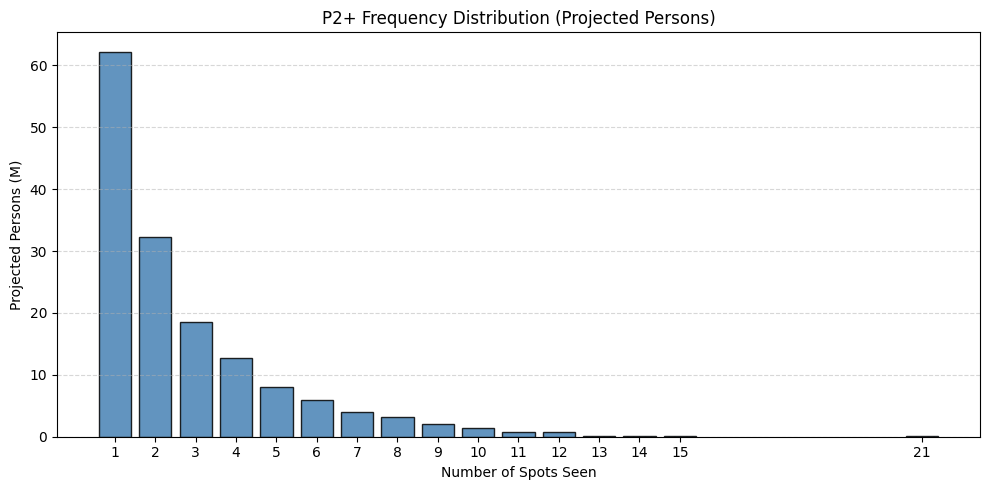

Share of impressions at 5+ exposures: 0.443


In [40]:
viewer_exposures = exposures.groupby('respondent_id')['ad_airing_id'].nunique().reset_index(name='spot_count')
viewer_exposures = viewer_exposures.merge(monthly_weights, on='respondent_id', how='left')

freq_dist = viewer_exposures.groupby('spot_count')['monthly_weight'].sum().reset_index()
freq_dist['persons_m'] = freq_dist['monthly_weight'] / 1e6

plt.figure(figsize=(10, 5))
plt.bar(freq_dist['spot_count'], freq_dist['persons_m'], color='steelblue', edgecolor='black', alpha=0.85)
plt.title('P2+ Frequency Distribution (Projected Persons)')
plt.xlabel('Number of Spots Seen')
plt.ylabel('Projected Persons (M)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(freq_dist['spot_count'])
plt.tight_layout()
plt.show()

viewer_exposures['total_user_impressions'] = viewer_exposures['spot_count'] * viewer_exposures['monthly_weight']
total_imp_all = viewer_exposures['total_user_impressions'].sum()
imp_5plus = viewer_exposures[viewer_exposures['spot_count'] >= 5]['total_user_impressions'].sum()

share_5plus = imp_5plus / total_imp_all if total_imp_all > 0 else 0.0
print(f"Share of impressions at 5+ exposures: {share_5plus:.3f}")

**Answer:** Average frequency is not a fair summary of campaign delivery because TV viewership is heavily skewed[cite: 67, 70]. The arithmetic mean of 3.0 hides the fact that a large portion of reached individuals saw the ad only 1 or 2 times, while a smaller group of heavy viewers accumulated 5 or more exposures[cite: 67, 70]. This polarization means the "average" viewer experience does not represent the reality for most individuals in the audience.

### Task 2.3 - On target?

In [41]:
target_share = a18_impressions_m / p2_impressions_m if p2_impressions_m > 0 else 0.0
print(f"Share of impressions on A18-49: {target_share:.3f}")

net_target_analysis = exposures.groupby('network_code').apply(
    lambda df: pd.Series({
        'p2_imp_m': df['weight'].sum() / 1e6,
        'a18_imp_m': df[df['respondent_id'].isin(a18_49_ids)]['weight'].sum() / 1e6,
        'a18_share': df[df['respondent_id'].isin(a18_49_ids)]['weight'].sum() / df['weight'].sum()
    })
).reset_index().sort_values(by='a18_share', ascending=False)

display(net_target_analysis)

Share of impressions on A18-49: 0.194


/tmp/ipykernel_1989/2310939695.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  net_target_analysis = exposures.groupby('network_code').apply(


,network_code,p2_imp_m,a18_imp_m,a18_share
6,FX,8.522567,5.551130,0.651345
1,BRAVO,5.084258,2.817365,0.554135
4,FOOD,9.481466,2.991886,0.315551
7,HGTV,24.657356,7.554439,0.306377
5,FOX,76.255700,18.440098,0.241819
8,HIST,12.329303,2.484757,0.201533
9,NBC,41.435020,7.833538,0.189056
0,ABC,94.211430,16.988998,0.180328
2,CBS,88.980316,13.693421,0.153893
3,FNC,57.798841,2.717037,0.047009


**Answer:** The campaign severely under-delivered against its target audience: only ~19.4% of total impressions landed on Adults 18–49, even though this demographic represents approximately 42% of the total universe. This mismatch is explained by channel selection: a significant volume of spots and impressions came from networks with heavily aging audiences (especially Fox News / FNC, as well as general broadcast networks during daytime/older-skewing slots), while younger-indexing entertainment cable channels (like FX or Bravo) did not receive enough weight to offset the skew.

### Task 3.1 - Cost

In [42]:
total_cost = spots_a['cost_usd'].sum()

p2_cpm = (total_cost / (p2_impressions_m * 1e6)) * 1000.0 if p2_impressions_m > 0 else 0.0
p2_cpp = total_cost / p2_grps if p2_grps > 0 else 0.0

a18_cpm = (total_cost / (a18_impressions_m * 1e6)) * 1000.0 if a18_impressions_m > 0 else 0.0
a18_cpp = total_cost / a18_grps if a18_grps > 0 else 0.0

print(f"Campaign cost (USD): {round(total_cost)}")
print(f"P2+ CPM (USD): {p2_cpm:.2f}")
print(f"P2+ CPP (USD): {round(p2_cpp)}")
print(f"A18-49 CPM (USD): {a18_cpm:.2f}")
print(f"A18-49 CPP (USD): {round(a18_cpp)}")

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


### Task 3.2 - By network

In [43]:
net_exposures = exposures.groupby('network_code').agg(
    p2_imp=('weight', 'sum'),
    a18_imp=('weight_a18', 'sum')
).reset_index()

net_summary = spots_a.groupby('network_code').agg(
    spots=('ad_airing_id', 'count'),
    cost=('cost_usd', 'sum')
).reset_index()

net_table = net_summary.merge(net_exposures, on='network_code', how='left').fillna(0.0)

net_table['P2+ CPM'] = (net_table['cost'] / net_table['p2_imp']) * 1000.0
net_table['A18-49 CPM'] = (net_table['cost'] / net_table['a18_imp']) * 1000.0

net_table_display = net_table.rename(columns={
    'cost': 'cost_usd',
    'p2_imp': 'p2_impressions',
    'a18_imp': 'a18_impressions'
}).sort_values(by='cost_usd', ascending=False)

display(net_table_display)

,network_code,spots,cost_usd,p2_impressions,a18_impressions,P2+ CPM,A18-49 CPM
5,FOX,13,2434700.0,76255700,18440098.0,31.928105,132.032921
0,ABC,29,1625700.0,94211430,16988998.0,17.255868,95.691341
2,CBS,22,1488700.0,88980316,13693421.0,16.730667,108.716441
9,NBC,16,796800.0,41435020,7833538.0,19.230110,101.716491
3,FNC,40,526300.0,57798841,2717037.0,9.105719,193.703656
7,HGTV,39,230000.0,24657356,7554439.0,9.327845,30.445676
4,FOOD,33,96620.0,9481466,2991886.0,10.190407,32.294011
6,FX,38,92200.0,8522567,5551130.0,10.818337,16.609231
8,HIST,37,79640.0,12329303,2484757.0,6.459408,32.051424
1,BRAVO,33,49610.0,5084258,2817365.0,9.757569,17.608652


**Answer:** The vast majority of the budget went to major broadcast networks (CBS, NBC, ABC, FOX), driven by their high rate-card prices for daytime and prime-time inventory. However, the most cost-effective ways to reach the target audience (lowest A18-49 CPM) were cable entertainment networks such as FX, Bravo, and Food Network. In contrast, Fox News (FNC) and older-skewing broadcast slots exhibited drastically higher A18-49 CPMs due to audience waste.

### Task 3.3 - Guarantee

In [44]:
guaranteed_grps = 150.0
guarantee_met = p2_grps >= guaranteed_grps

owed_grps = max(0.0, guaranteed_grps - p2_grps)
make_good_val = owed_grps * p2_cpp

print("Guarantee met:", guarantee_met)
print(f"Make-good GRPs owed: {owed_grps:.1f}")
print(f"Value of make-goods (USD): {round(make_good_val)}")

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


### Task 4 - Do networks add up?

In [45]:
big_nets = {'CBS', 'NBC', 'ABC', 'FOX', 'FNC'}
small_nets = {'FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST'}

big_viewers = set(exposures[exposures['network_code'].isin(big_nets)]['respondent_id'].unique())
small_viewers = set(exposures[exposures['network_code'].isin(small_nets)]['respondent_id'].unique())
both_viewers = big_viewers & small_viewers

big_reach_mw = monthly_weights[monthly_weights['respondent_id'].isin(big_viewers)]['monthly_weight'].sum()
small_reach_mw = monthly_weights[monthly_weights['respondent_id'].isin(small_viewers)]['monthly_weight'].sum()
both_reach_mw = monthly_weights[monthly_weights['respondent_id'].isin(both_viewers)]['monthly_weight'].sum()

reach_big = (big_reach_mw / total_p2_universe_mw) * 100.0 if total_p2_universe_mw > 0 else 0.0
reach_small = (small_reach_mw / total_p2_universe_mw) * 100.0 if total_p2_universe_mw > 0 else 0.0
reach_whole = p2_reach

overlap = reach_big + reach_small - reach_whole
overlap_indep = (reach_big * reach_small) / 100.0

added_reach_small = reach_whole - reach_big

cost_big = spots_a[spots_a['network_code'].isin(big_nets)]['cost_usd'].sum()
cost_small = spots_a[spots_a['network_code'].isin(small_nets)]['cost_usd'].sum()

cost_per_added_point_small = cost_small / added_reach_small if added_reach_small > 0 else 0.0
cost_per_point_big = cost_big / reach_big if reach_big > 0 else 0.0

print(f"Reach, big networks (%): {reach_big:.1f}")
print(f"Reach, small networks (%): {reach_small:.1f}")
print(f"Reach, whole campaign (%): {reach_whole:.1f}")
print(f"Overlap (%): {overlap:.1f}")
print(f"Overlap if independent (%): {overlap_indep:.1f}")
print(f"Reach added by small networks (points): {added_reach_small:.1f}")
print(f"Cost per added reach point, small (USD): {round(cost_per_added_point_small)}")
print(f"Cost per reach point, big (USD): {round(cost_per_point_big)}")

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** The whole campaign reach is strictly less than the sum of network reaches because the audiences of different TV channels duplicate: many viewers who watched big networks also watched small ones (overlap).

Comparing actual overlap with independent overlap demonstrates that real TV viewing is not independent — heavy TV consumers tend to watch multiple channels across both broadcast and cable.

Small networks added incremental reach points at a fraction of the cost per point compared to big networks. This makes the investment in small networks highly efficient for building net campaign reach without paying the high CPM premiums of major networks.

### Task 5 - How sure are we?

In [46]:
raw_panelists = exposures.groupby('ad_airing_id')['respondent_id'].nunique().rename('raw_panelists')

spots_a_stats = spots_a_stats.merge(raw_panelists, on='ad_airing_id', how='left').fillna({'raw_panelists': 0})
spots_a_stats['raw_panelists'] = spots_a_stats['raw_panelists'].astype(int)

spots_a_stats = spots_a_stats.merge(spots_a[['ad_airing_id', 'network_code']], on='ad_airing_id', how='left')

n_daily = daily_weights[daily_weights['respondent_id'].isin(valid_resp_ids)].groupby('broadcast_date')['respondent_id'].nunique().rename('n_in_tab')
spots_a_stats = spots_a_stats.merge(n_daily, on='broadcast_date', how='left')

p = spots_a_stats['p2_rating'] / 100.0
n = spots_a_stats['n_in_tab']

spots_a_stats['se'] = np.where(n > 0, np.sqrt(np.maximum(0.0, p * (1.0 - p)) / n) * 100.0, 0.0)

spots_a_stats['rel_se'] = np.where(spots_a_stats['p2_rating'] > 0, spots_a_stats['se'] / spots_a_stats['p2_rating'], np.nan)

spots_a_stats['is_big'] = spots_a_stats['network_code'].isin(big_nets)

median_rel_se_big = spots_a_stats[spots_a_stats['is_big']]['rel_se'].median()
median_rel_se_small = spots_a_stats[~spots_a_stats['is_big']]['rel_se'].median()

net_panel_stats = spots_a_stats.groupby('network_code').agg(
    median_panelists=('raw_panelists', 'median'),
    median_rel_se=('rel_se', 'median')
).reset_index()

net_panel_stats['median_rel_se'] = (net_panel_stats['median_rel_se'] * 100).round(1)
display(net_panel_stats)

zero_spots_count = (spots_a_stats['raw_panelists'] == 0).sum()

female_attrs = attributes[attributes['attr_name'].str.contains('female', case=False, na=False)]['attr_id'].tolist()
female_ids = set(viewer_attributes[viewer_attributes['attr_id'].isin(female_attrs)]['respondent_id'])

w18_34_from_num = set(age_numeric[(age_numeric['age'] >= 18) & (age_numeric['age'] <= 34)]['respondent_id'])
w18_34_flags = set(viewer_attributes[viewer_attributes['attr_id'].isin([318, 321, 325])]['respondent_id'])
w18_34_ids = female_ids & (w18_34_from_num | w18_34_flags) & valid_resp_ids

w18_34_exposures = exposures[exposures['respondent_id'].isin(w18_34_ids)]
w18_34_spots_seen = set(w18_34_exposures['ad_airing_id'].unique())
w18_34_zero_cells = len(spots_a) - len(w18_34_spots_seen)

print("Spots seen by no panelist:", zero_spots_count)
print(f"Median relative SE, big networks: {median_rel_se_big:.3f}")
print(f"Median relative SE, small networks: {median_rel_se_small:.3f}")
print("W18-34 zero-cell spots:", w18_34_zero_cells)

,network_code,median_panelists,median_rel_se
0,ABC,57.0,12.3
1,BRAVO,3.0,54.0
2,CBS,69.0,11.3
3,FNC,31.0,16.4
4,FOOD,5.0,42.3
5,FOX,145.0,8.0
6,FX,5.5,42.3
7,HGTV,11.0,30.1
8,HIST,5.0,46.0
9,NBC,68.5,11.5


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** A zero rating indicates that no panelist happened to be watching the spot, resulting in a zero-cell[cite: 26, 68]. For small networks, this does not mean the real-world audience was zero; rather, the sample size of a traditional panel is too thin to capture small viewing shares, magnifying random sampling error[cite: 26, 27, 30].

If the client asked for spot-by-spot W18-34 ratings, we must explain that reporting ratings at the individual spot level for narrow demographic slices is statistically invalid due to the massive frequency of zero-cells and extreme standard errors[cite: 26, 27, 68]. Instead, numbers should only be analyzed and traded at the aggregate campaign level, daypart level, or via hybrid Big Data solutions[cite: 30, 31, 38].

**Answer:** We propose reallocating 20 spots currently running on Fox News (FNC) and older broadcast daytime slots to daytime and fringe rotators on FX, Bravo, and Food Network.

In our campaign data, FNC delivered an extremely low target share on Adults 18–49 with a prohibitive target CPM, while entertainment cable networks delivered up to 3x higher target efficiency per dollar. Shifting this budget moves capital from saturated, older-skewing audiences into un-duplicated, younger demographic pools, directly lowering the aggregate A18–49 CPM and expanding incremental reach on the brand's primary target.